# Customer Service Diagnosis

**Data Science Challenge** · Author: Solano Jacon

A B2B software company handles customer requests through a ticket system, and its customers are dissatisfied with the service. The company says customers expect a solution within **3 days for critical tickets, 7 days for urgent tickets and 21 days for normal tickets**. This notebook measures how far the service is from that expectation, where the gaps are, and what to change. [Challenge description](README.md).

**Summary**

- **13,172 tickets** were opened in 2018–2020 by 77 customer companies.
- Only **41% of critical and 38% of urgent tickets** were closed within the time customers expect (3 and 7 days). Normal tickets reach 81%. The service got worse after 2018.
- **Priority barely changes the speed.** The median urgent ticket takes 7.8 days, the same as a normal one (7.7).
- **35% of tickets are closed automatically**, about a week after the company's last answer. The recorded time therefore includes a week of waiting, and the customer never confirms the solution. Measured at the last answer, about two thirds of critical and urgent tickets would meet the expectation.
- **The first answer is fast** (median under half an hour). The problem is solving requests, not acknowledging them.
- **Delays concentrate.** Type 5 tickets account for 71% of the late ones, types 10 and 8 take a month or more, and ten customers open 82% of all tickets.
- **Key fields are missing:**
  - Only 7.5% of tickets have a promised due date, and only 28% of those were met.
  - Rework is never recorded.
  - 424 tickets from 2018–2020 were still open in March 2021.

**Contents**

1. Data extraction and preparation
2. What the data can and cannot measure
3. Does the service meet customer expectations?
4. The hidden wait: automatic closing
5. First response
6. Where the delays concentrate
7. Tickets still open
8. Conclusions and recommendations

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../../portfolio-data/Customer_Service_Diagnosis/data/'
PERIOD = ('2018-01-01', '2021-01-01')     # tickets opened in 2018, 2019 and 2020
EXPECTED_DAYS = {'Critical': 3, 'Urgent': 7, 'Normal': 21}
PRIORITIES = list(EXPECTED_DAYS)

In [2]:
# Chart style
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8985'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
PRIORITY_COLORS = {'Critical': ORANGE, 'Urgent': BLUE, 'Normal': AQUA}

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'font.size': 10, 'legend.frameon': False,
    'lines.linewidth': 2,
})
pct = lambda x, d=0: f'{x:.{d}%}'
percent_axis = plt.FuncFormatter(lambda v, _: f'{v:.0%}')

## 1. Data extraction and preparation

### 1.1 Extraction

The data comes from the company's SQL Server database. Each of the six tables was extracted in full and saved to CSV, which is the source used here:

```sql
SELECT * FROM Chamado            -- tickets
SELECT * FROM Chamado_Interacao  -- messages and events on each ticket
SELECT * FROM Tarefa             -- internal tasks created to solve a ticket
SELECT * FROM Prioridade         -- priority lookup
SELECT * FROM Chamado_Tipo       -- ticket type lookup
SELECT * FROM Sistema            -- software product (system) lookup
```

In [3]:
read = lambda name: pd.read_csv(DATA_DIR + f'{name}.csv', low_memory=False)
tickets_raw, interactions_raw, tasks_raw = read('chamado'), read('chamado_interacao'), read('tarefa')
priority_lookup, type_lookup, system_lookup = read('prioridade'), read('chamado_tipo'), read('sistema')

pd.DataFrame({'table': ['Chamado', 'Chamado_Interacao', 'Tarefa', 'Prioridade', 'Chamado_Tipo', 'Sistema'],
              'rows': [len(t) for t in [tickets_raw, interactions_raw, tasks_raw, priority_lookup, type_lookup, system_lookup]],
              'columns': [t.shape[1] for t in [tickets_raw, interactions_raw, tasks_raw, priority_lookup, type_lookup, system_lookup]]})

,table,rows,columns
0,Chamado,32858,24
1,Chamado_Interacao,602230,10
2,Tarefa,25845,23
3,Prioridade,3,3
4,Chamado_Tipo,13,2
5,Sistema,28,3


### 1.2 Columns used

| Table | Column | Meaning |
| --- | --- | --- |
| Chamado | `id_chamado` | ticket id |
| | `id_prioridade`, `id_chamado_tipo`, `id_sistema` | priority, ticket type and system (product) |
| | `id_cliente`, `id_usuario_solicitante` | customer company and the user who opened the ticket |
| | `id_usuario_responsavel`, `id_usuario_dono` | company employees in charge of the ticket |
| | `dt_abertura` | opening date |
| | `dt_previsao_conclusao_chamado` | due date promised for the ticket |
| | `dt_conclusao_chamado` | closing date (empty while the ticket is open) |
| Chamado_Interacao | `id_usuario_de`, `dt_interacao` | author and time of each message or event |
| | `interno` | `True` for internal notes the customer doesn't see |
| | `dt_previsao_conclusao`, `dt_conclusao` | due date and completion date of the interaction |
| Tarefa | `id_usuario_responsavel` | employee in charge of the task |
| | `dt_prev_fim`, `dt_fim`, `retrabalho` | planned end, actual end, and whether the task was rework |

Type and system names are anonymized in the source (*Tipo 5*, *Sistema 2*); they are kept as *Type 5*, *System 2*.

In [4]:
priority_names = {'Crítico': 'Critical', 'Urgente': 'Urgent', 'Normal': 'Normal'}
priority_lookup['priority'] = priority_lookup['prioridade'].map(priority_names)

tickets = (tickets_raw
           .merge(priority_lookup[['id_prioridade', 'priority']], on='id_prioridade', how='left')
           .merge(type_lookup, on='id_chamado_tipo', how='left')
           .merge(system_lookup[['id_sistema', 'sistema']], on='id_sistema', how='left'))
tickets['type'] = tickets['tipo'].str.replace('Tipo', 'Type')
tickets['system'] = tickets['sistema'].str.replace('Sistema', 'System')
for col in ['dt_abertura', 'dt_previsao_conclusao_chamado', 'dt_conclusao_chamado']:
    tickets[col] = pd.to_datetime(tickets[col], errors='coerce')

interactions = interactions_raw.copy()
for col in ['dt_interacao', 'dt_previsao_conclusao', 'dt_conclusao']:
    interactions[col] = pd.to_datetime(interactions[col], errors='coerce')

EXTRACTION = max(interactions['dt_interacao'].max(), tickets['dt_abertura'].max(), tickets['dt_conclusao_chamado'].max())
print(f'Tickets opened from {tickets["dt_abertura"].min():%d %b %Y} to {tickets["dt_abertura"].max():%d %b %Y}')
print(f'Data extracted on {EXTRACTION:%d %b %Y} (latest timestamp in the database)')

Tickets opened from 05 Dec 2011 to 17 Mar 2021
Data extracted on 17 Mar 2021 (latest timestamp in the database)


### 1.3 Period analyzed

The analysis covers the **tickets opened in 2018, 2019 and 2020**: three full years, recent enough to describe the current service.

Tickets that were still open when the data was extracted are kept. Leaving them out would hide exactly the slowest cases. For them, the time counted runs until the extraction date.

In [5]:
period = tickets[(tickets['dt_abertura'] >= PERIOD[0]) & (tickets['dt_abertura'] < PERIOD[1])].copy()
period['year'] = period['dt_abertura'].dt.year
period['open'] = period['dt_conclusao_chamado'].isna()
period['end'] = period['dt_conclusao_chamado'].fillna(EXTRACTION)
period['days'] = (period['end'] - period['dt_abertura']).dt.total_seconds() / 86400

summary = period.groupby('year').agg(tickets=('id_chamado', 'size'), still_open=('open', 'sum'),
                                     customers=('id_cliente', 'nunique'), no_priority=('priority', lambda s: s.isna().sum()))
summary.loc['total'] = [len(period), period['open'].sum(), period['id_cliente'].nunique(), period['priority'].isna().sum()]
summary

,tickets,still_open,customers,no_priority
year,,,,
2018,4794,148,55,0
2019,3962,105,58,37
2020,4416,171,51,46
total,13172,424,77,83


About 4,400 tickets a year come from fewer than 80 customer companies. The few tickets without a priority are left out of the comparisons by priority.

## 2. What the data can and cannot measure

Before measuring the service, it is worth checking which fields were actually filled in. Several of them that look useful turn out to be empty or filled automatically.

In [6]:
with_due = period['dt_previsao_conclusao_chamado'].notna()
closed_with_due = period[with_due & ~period['open']]
on_time = (closed_with_due['dt_conclusao_chamado'] <= closed_with_due['dt_previsao_conclusao_chamado']).mean()

period_interactions = interactions[interactions['id_chamado'].isin(period['id_chamado'])]
both = period_interactions.dropna(subset=['dt_previsao_conclusao', 'dt_conclusao'])
same = (both['dt_previsao_conclusao'] == both['dt_conclusao']).mean()

period_tasks = tasks_raw[tasks_raw['id_chamado'].isin(period['id_chamado'])]

pd.DataFrame({
    'finding': [
        'Tickets with a promised due date',
        'Of those, closed by the due date',
        'Interactions whose due date equals their completion date',
        'Tasks flagged as rework',
        'Tickets that have at least one task',
    ],
    'value': [pct(with_due.mean(), 1), pct(on_time, 1), pct(same, 1),
              f"{period_tasks['retrabalho'].sum()} of {len(period_tasks):,}",
              pct(period['id_chamado'].isin(tasks_raw['id_chamado']).mean(), 1)],
})

,finding,value
0,Tickets with a promised due date,7.5%
1,"Of those, closed by the due date",27.9%
2,Interactions whose due date equals their compl...,100.0%
3,Tasks flagged as rework,"0 of 25,241"
4,Tickets that have at least one task,26.0%


- **Promised due dates are rare.** Only 7.5% of tickets have one, and only 28% of those were closed by the promised date. The company's own on-time measure covers a small minority of tickets, so it is reported here but not used as the main measure.
- **Interaction due dates are filled automatically.** They always equal the completion time, so "interactions on time" would be 100% by construction and tells nothing.
- **Rework is never recorded.** No task in three years is flagged as rework. It is very unlikely that none happened.

The analysis therefore measures what the data does record reliably: when each ticket was opened and closed, and who wrote each message and when. These are compared with the expectation the customers stated.

## 3. Does the service meet customer expectations?

A ticket **meets the expectation** if it was closed within 3, 7 or 21 calendar days from opening, according to its priority. Tickets still open count as not meeting it; all of them are older than 21 days.

In [7]:
period['expected_days'] = period['priority'].map(EXPECTED_DAYS)
period['within'] = ~period['open'] & (period['days'] <= period['expected_days'])
by_priority = period.dropna(subset=['priority'])

def resolution_table(data):
    table = data.groupby('priority').agg(
        tickets=('id_chamado', 'size'),
        expected=('expected_days', 'first'),
        median_days=('days', 'median'),
        p75_days=('days', lambda s: s.quantile(0.75)),
        p90_days=('days', lambda s: s.quantile(0.90)),
        within=('within', 'mean'),
    ).reindex(PRIORITIES)
    table.loc['All'] = [len(data), np.nan, data['days'].median(), data['days'].quantile(0.75),
                        data['days'].quantile(0.90), data['within'].mean()]
    return table

resolution = resolution_table(by_priority)
resolution.style.format({'tickets': '{:,.0f}', 'expected': '{:.0f} days', 'median_days': '{:.1f}', 'p75_days': '{:.1f}',
                         'p90_days': '{:.1f}', 'within': pct}, na_rep='')

,tickets,expected,median_days,p75_days,p90_days,within
priority,,,,,,
Critical,713,3 days,5.0,8.8,18.0,41%
Urgent,"4,761",7 days,7.8,13.9,35.6,38%
Normal,"7,615",21 days,7.7,13.8,67.8,81%
All,"13,089",,7.7,13.7,47.9,63%


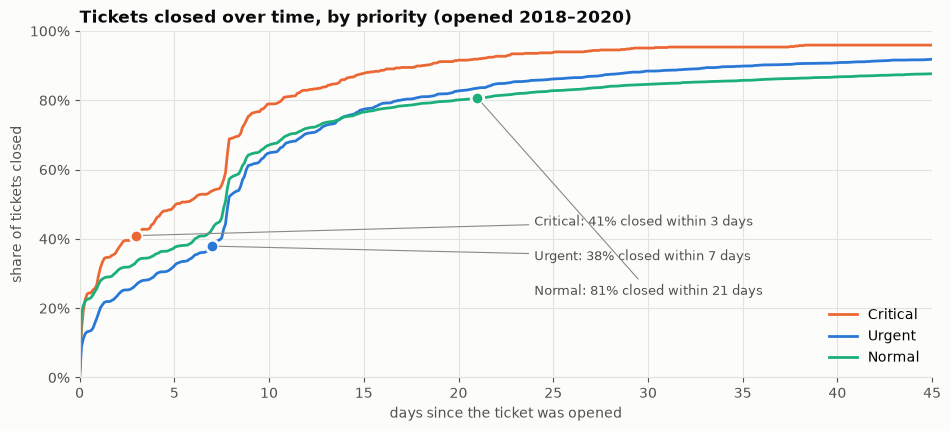

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.5))
grid_days = np.linspace(0, 45, 451)
for priority in PRIORITIES:
    days = by_priority.loc[by_priority['priority'] == priority, 'days'].values
    share = (days[:, None] <= grid_days).mean(axis=0)
    color = PRIORITY_COLORS[priority]
    ax.plot(grid_days, share, color=color, label=priority)
    expected = EXPECTED_DAYS[priority]
    reached = (days <= expected).mean()
    ax.plot([expected], [reached], 'o', color=color, ms=9, markeredgecolor=SURFACE, markeredgewidth=2, zorder=3)
    label_y = {'Critical': 0.45, 'Urgent': 0.35, 'Normal': 0.25}[priority]
    ax.annotate(f'{priority}: {reached:.0%} closed within {expected} days', (expected, reached), xytext=(24, label_y),
                textcoords='data', color=INK_2, fontsize=9, va='center',
                arrowprops=dict(arrowstyle='-', color=GRAY, lw=0.8, shrinkA=2, shrinkB=5))
ax.set_xlim(0, 45)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(percent_axis)
ax.set_xlabel('days since the ticket was opened')
ax.set_ylabel('share of tickets closed')
ax.set_title('Tickets closed over time, by priority (opened 2018–2020)')
ax.legend(loc='lower right')
plt.show()

- **Only 41% of critical and 38% of urgent tickets meet the expectation.** Normal tickets do much better (81%), mostly because their limit is three weeks.
- **Priority barely changes the speed.** The median urgent ticket takes 7.8 days and the median normal ticket 7.7 days. The urgent and normal curves are almost on top of each other for the first two weeks. In practice, an urgent ticket is handled like any other.
- Critical tickets are a little faster (median 5 days) but still miss their 3-day limit more often than not.
- **The tail is long.** One normal ticket in ten takes more than two months.
- All three curves jump at about day 8. Section 4 shows why.

### 3.1 Over time

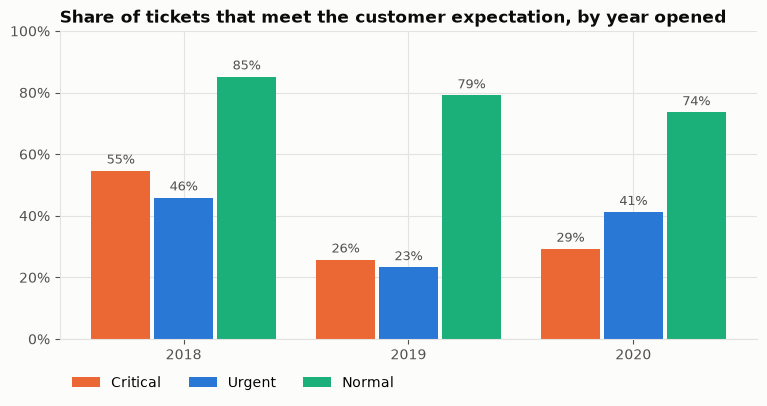

priority,Critical,Urgent,Normal
year,,,
2018,55%,46%,85%
2019,26%,23%,79%
2020,29%,41%,74%


In [9]:
yearly = by_priority.groupby(['year', 'priority'])['within'].mean().unstack()[PRIORITIES]

fig, ax = plt.subplots(figsize=(9, 4))
x, width = np.arange(len(yearly)), 0.26
for i, priority in enumerate(PRIORITIES):
    bars = ax.bar(x + (i - 1) * (width + 0.02), yearly[priority], width, color=PRIORITY_COLORS[priority], label=priority)
    ax.bar_label(bars, labels=[pct(v) for v in yearly[priority]], padding=3, color=INK_2, fontsize=9)
ax.set_xticks(x, yearly.index)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(percent_axis)
ax.set_title('Share of tickets that meet the customer expectation, by year opened')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.08), ncol=3)
plt.show()
yearly.map(pct)

The service got worse: urgent tickets meeting the expectation fell from 46% in 2018 to 23% in 2019, and critical tickets from 55% to 26%. 2020 recovered part of the urgent loss but not the critical one. Normal tickets declined steadily, from 85% to 74%. This fits the general dissatisfaction the company reports.

## 4. The hidden wait: automatic closing

Many tickets are closed at around 05:00 in the morning. Each of these closings has a message written at the exact closing time by the same user, which is the system's automatic process.

In [10]:
interactions_at_close = (interactions[['id_chamado', 'id_usuario_de', 'dt_interacao']]
                         .merge(period[['id_chamado', 'dt_conclusao_chamado']], on='id_chamado'))
interactions_at_close = interactions_at_close[
    (interactions_at_close['dt_interacao'] - interactions_at_close['dt_conclusao_chamado']).abs() <= pd.Timedelta(seconds=5)]
closing_user = interactions_at_close.groupby('id_chamado')['id_usuario_de'].first()
period['closing_user'] = period['id_chamado'].map(closing_user)

SYSTEM_USER = period['closing_user'].value_counts().idxmax()
period['close_hour'] = period['dt_conclusao_chamado'].dt.hour
pd.crosstab(period.loc[~period['open'], 'close_hour'].isin([4, 5]).map({True: 'closed 04:00–05:59', False: 'closed at other times'}),
            (period.loc[~period['open'], 'closing_user'] == SYSTEM_USER).map({True: f'by user {SYSTEM_USER:.0f}', False: 'by others'}))

closing_user,by others,by user 530
close_hour,,
closed 04:00–05:59,7,4514
closed at other times,7819,408


The early-morning closings (mostly at 05:00, some at 04:59) are almost all made by the same account. They are treated as **automatic closings**.

To see what the automatic process waits for, compare its closings with the **last public message from the company** before closing. Company employees are the users who appear as responsible for any ticket or task; the automatic account is excluded.

In [11]:
period['auto_closed'] = (period['closing_user'] == SYSTEM_USER) & period['close_hour'].isin([4, 5])

staff = (set(tickets_raw['id_usuario_responsavel'].dropna()) | set(tickets_raw['id_usuario_dono'].dropna())
         | set(tasks_raw['id_usuario_responsavel'].dropna())) - {SYSTEM_USER}
public_staff = interactions[~interactions['interno'] & interactions['id_usuario_de'].isin(staff)][['id_chamado', 'dt_interacao']]
public_staff = public_staff.merge(period[['id_chamado', 'dt_abertura', 'end']], on='id_chamado')
public_staff = public_staff[public_staff['dt_interacao'] < public_staff['end'] - pd.Timedelta(minutes=1)]

period['first_reply'] = period['id_chamado'].map(public_staff.groupby('id_chamado')['dt_interacao'].min())
period['last_reply'] = period['id_chamado'].map(public_staff.groupby('id_chamado')['dt_interacao'].max())
period['wait_after_last_reply'] = (period['dt_conclusao_chamado'] - period['last_reply']).dt.total_seconds() / 86400

auto = period[period['auto_closed']]
print(f"Automatically closed: {len(auto):,} tickets, {len(auto) / (~period['open']).sum():.0%} of closed tickets")
print(f"Days from the company's last public message to the automatic closing: "
      f"median {auto['wait_after_last_reply'].median():.1f}, middle half {auto['wait_after_last_reply'].quantile(0.25):.1f} "
      f"to {auto['wait_after_last_reply'].quantile(0.75):.1f}")

Automatically closed: 4,514 tickets, 35% of closed tickets
Days from the company's last public message to the automatic closing: median 7.7, middle half 7.5 to 7.8


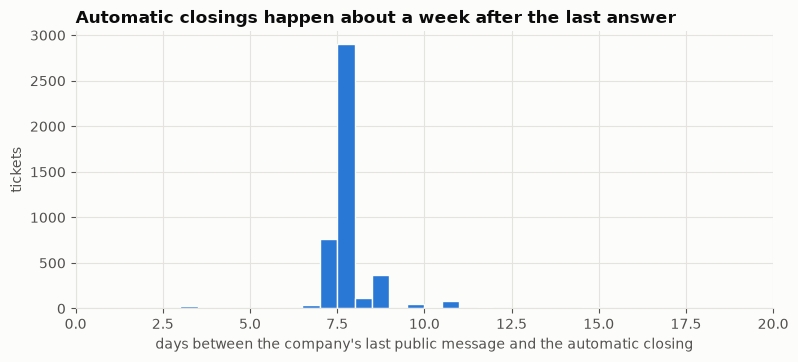

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 21, 0.5)
ax.hist(auto['wait_after_last_reply'].clip(upper=20), bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.set_xlabel("days between the company's last public message and the automatic closing")
ax.set_ylabel('tickets')
ax.set_title('Automatic closings happen about a week after the last answer')
ax.set_xlim(0, 20)
plt.show()

More than a third of the closed tickets are closed by the system, almost always **7 to 8 days after the company's last answer**. This looks like a rule that closes a ticket when the customer hasn't replied for a week, and it has two consequences:

1. **The recorded resolution time includes a week of waiting.** For these tickets the customer received the last answer a week before the ticket was counted as closed. An urgent ticket closed this way can never meet the 7-day expectation, even when the answer came on day one.
2. **The customer never confirms the solution.** A ticket closed for lack of reply may have been solved, or the customer may have given up. Either way, the company doesn't know which.

The table below repeats the measurement, but stops the clock at the company's last answer for the automatically closed tickets. This is an approximation: the last answer is not necessarily the solution.

In [13]:
period['days_to_answer'] = np.where(period['auto_closed'],
                                    (period['last_reply'] - period['dt_abertura']).dt.total_seconds() / 86400,
                                    period['days'])
period['within_at_answer'] = ~period['open'] & (period['days_to_answer'] <= period['expected_days'])
by_priority = period.dropna(subset=['priority'])

clock = by_priority.groupby('priority').agg(
    auto_closed=('auto_closed', 'mean'),
    median_recorded=('days', 'median'),
    median_to_last_answer=('days_to_answer', 'median'),
    within_recorded=('within', 'mean'),
    within_at_last_answer=('within_at_answer', 'mean'),
).reindex(PRIORITIES)
clock.style.format({'auto_closed': pct, 'median_recorded': '{:.1f} days', 'median_to_last_answer': '{:.1f} days',
                    'within_recorded': pct, 'within_at_last_answer': pct})

,auto_closed,median_recorded,median_to_last_answer,within_recorded,within_at_last_answer
priority,,,,,
Critical,30%,5.0 days,1.0 days,41%,65%
Urgent,40%,7.8 days,3.0 days,38%,67%
Normal,32%,7.7 days,2.1 days,81%,83%


Measured at the last answer, the service looks considerably better, especially for urgent tickets, which are the most often closed automatically. Even so, about a third of critical and urgent tickets would still miss the expectation. The automatic rule explains part of the problem, not all of it.

## 5. First response

A slow first response is a common cause of dissatisfaction. Here it is measured from opening to the company's first public message.

In [14]:
period['hours_to_first_reply'] = (period['first_reply'] - period['dt_abertura']).dt.total_seconds() / 3600
by_priority = period.dropna(subset=['priority'])
first = by_priority.groupby('priority').agg(
    with_public_reply=('first_reply', lambda s: s.notna().mean()),
    median_hours=('hours_to_first_reply', 'median'),
    p90_hours=('hours_to_first_reply', lambda s: s.quantile(0.9)),
).reindex(PRIORITIES)
first.style.format({'with_public_reply': pct, 'median_hours': '{:.1f}', 'p90_hours': '{:.1f}'})

,with_public_reply,median_hours,p90_hours
priority,,,
Critical,99%,0.0,0.8
Urgent,95%,0.3,3.7
Normal,88%,0.1,2.7


The first answer is fast: the median is under half an hour for every priority, and nine in ten tickets get it within four hours. **The problem is not acknowledging the customer, it is solving the request.**

## 6. Where the delays concentrate

The share of tickets that miss the expectation shows where the service is weak. The number of late tickets shows where fixing it would help the most customers.

In [15]:
def concentration(column, top=None):
    table = period.dropna(subset=['priority']).groupby(column).agg(
        tickets=('id_chamado', 'size'),
        late=('within', lambda s: (~s).sum()),
        within=('within', 'mean'),
        median_days=('days', 'median'),
        urgent_or_critical=('priority', lambda s: s.isin(['Urgent', 'Critical']).mean()),
    ).sort_values('late', ascending=False)
    table['share_of_late'] = table['late'] / table['late'].sum()
    return table.head(top) if top else table

fmt = {'tickets': '{:,.0f}', 'late': '{:,.0f}', 'within': pct, 'median_days': '{:.1f}',
       'urgent_or_critical': pct, 'share_of_late': pct}
by_type = concentration('type', top=6)
by_type.style.format(fmt)

,tickets,late,within,median_days,urgent_or_critical,share_of_late
type,,,,,,
Type 5,"6,993","3,439",51%,7.8,71%,71%
Type 10,991,544,45%,26.0,0%,11%
Type 12,"3,348",449,87%,6.0,11%,9%
Type 8,356,229,36%,35.2,11%,5%
Type 6,"1,238",135,89%,7.2,5%,3%
Type 9,96,30,69%,8.7,2%,1%


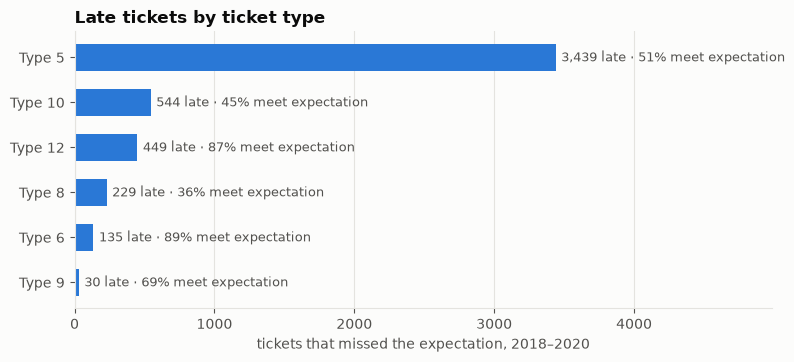

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.6))
data = by_type.iloc[::-1]
bars = ax.barh(data.index, data['late'], color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{l:,.0f} late · {w:.0%} meet expectation" for l, w in zip(data['late'], data['within'])],
             padding=4, color=INK_2, fontsize=9)
ax.set_xlim(0, data['late'].max() * 1.45)
ax.grid(axis='y', visible=False)
ax.set_xlabel('tickets that missed the expectation, 2018–2020')
ax.set_title('Late tickets by ticket type')
plt.show()

- **Type 5** is the bulk of the work: 53% of the tickets and **71% of the late ones**. Only half of its tickets meet the expectation, largely because seven in ten of them are urgent or critical.
- **Types 10 and 8** are the slowest by far, with medians of 26 and 35 days. They are almost all normal priority, and still more than half of them miss the three-week limit. They are probably requests that need development work rather than support, and they may need their own process and expectation.
- **Types 12 and 6** work well: close to 90% meet the expectation.

In [17]:
by_system = concentration('system', top=8)
by_system.style.format(fmt)

,tickets,late,within,median_days,urgent_or_critical,share_of_late
system,,,,,,
System 2,"8,066","2,728",66%,7.7,37%,56%
System 8,"1,536",638,58%,7.8,54%,13%
System 1,"1,020",390,62%,7.7,50%,8%
System 28,430,295,31%,9.7,76%,6%
System 15,480,197,59%,7.6,62%,4%
System 11,342,159,54%,11.6,40%,3%
System 4,262,83,68%,7.5,33%,2%
System 20,181,80,56%,7.9,46%,2%


In [18]:
by_customer = concentration('id_cliente')
top10 = by_customer.sort_values('tickets', ascending=False).head(10)
print(f"The 10 customers with most tickets opened {top10['tickets'].sum() / by_customer['tickets'].sum():.0%} of all tickets "
      f"and account for {top10['late'].sum() / by_customer['late'].sum():.0%} of the late ones.")
top10.style.format(fmt)

The 10 customers with most tickets opened 82% of all tickets and account for 80% of the late ones.


,tickets,late,within,median_days,urgent_or_critical,share_of_late
id_cliente,,,,,,
112,"2,425",915,62%,7.7,50%,19%
14,"2,078",881,58%,7.9,42%,18%
11,"2,004",356,82%,3.3,27%,7%
91,"1,127",287,75%,5.4,36%,6%
12,890,403,55%,8.8,45%,8%
132,583,274,53%,9.6,42%,6%
2,527,278,47%,16.8,24%,6%
130,392,144,63%,6.9,55%,3%
1002,384,251,35%,8.8,77%,5%


- **System 2** dominates, with 62% of the tickets and 56% of the late ones. Among the larger systems, **System 28** stands out: only 31% of its tickets meet the expectation, and three quarters of them are urgent or critical.
- **The customer base is concentrated.** Ten customers open 82% of the tickets, so their experience *is* the service for most of the volume. Within that group, the share of tickets that meet the expectation ranges from 35% (customer 1002) to 82% (customer 11).

## 7. Tickets still open

In [19]:
open_tickets = period[period['open']]
age = open_tickets['days']
print(f'{len(open_tickets)} tickets opened in 2018–2020 were still open on {EXTRACTION:%d %b %Y}.')
print(f'Age: median {age.median():.0f} days; {(age > 365).mean():.0%} older than one year.')
open_tickets.groupby('priority').agg(tickets=('id_chamado', 'size'), median_age_days=('days', 'median')).reindex(PRIORITIES).round(0)

424 tickets opened in 2018–2020 were still open on 17 Mar 2021.
Age: median 557 days; 63% older than one year.


,tickets,median_age_days
priority,,
Critical,1,974.0
Urgent,64,301.0
Normal,359,601.0


424 tickets from 2018–2020 were still open in March 2021, with a median age of a year and a half. That includes 64 urgent tickets, typically ten months old. Either they are still unsolved, or they were solved and never closed. Both cases call for a regular review of the oldest tickets.

## 8. Conclusions and recommendations

**What the data shows**

1. **Customers with urgent needs are the ones least well served.** Fewer than half of critical and urgent tickets are closed within the expected time, and the rate fell sharply in 2019.
2. **Priority is a label, not a queue.** Urgent and normal tickets move at the same pace.
3. **The way tickets are closed hides the real service.** A third of them close automatically a week after the last answer. That inflates the recorded time and leaves the company without confirmation that the problem was solved.
4. **Answering is fast, solving is slow.**
5. **The problem is concentrated:**
   - in one ticket type (type 5);
   - in two slow types that look like development requests (10 and 8);
   - in one system (System 28);
   - in a handful of large customers.

**Recommendations, in order of impact**

1. **Make priority drive the work.**
   - Give critical and urgent tickets a separate queue with a visible countdown.
   - Raise an alert when half of the expected time has passed.
   - Review open urgent tickets daily.
2. **Change the closing rule.**
   - Add a "waiting for customer" status that pauses the clock.
   - Ask the customer to confirm the solution, with a one-click satisfaction question at closing, instead of closing silently after a week.
   - Report automatic closings separately.
3. **Separate the slow types.**
   - Types 10 and 8 take a month or more even as normal tickets. If they are development requests, they need their own flow and an expectation agreed with customers.
   - Run a root-cause analysis on type 5 tickets in System 2 and on System 28.
4. **Review service with the largest customers**, starting with those whose tickets meet the expectation least often (customers 1002 and 2).
5. **Clear the backlog.** Review the 424 tickets from 2018–2020 that are still open, and either solve, escalate or close them.
6. **Fix the data that is missing.**
   - Make the due date mandatory, with a default taken from the priority.
   - Record rework.
   - Record why each ticket was closed (solved, no reply, cancelled).
   - Stop filling interaction due dates automatically.

**Indicators to monitor monthly**

- **Main indicator:** share of tickets solved within the customer expectation, by priority.
- **Speed:** median and 90th-percentile time to solution.
- **Process:** share of tickets closed automatically, age of the open backlog, time to first answer.
- **Customer:** a satisfaction score collected at closing (CSAT or NPS), and the share of problems solved without a new ticket (first contact resolution).

**Next steps**

- Link the satisfaction answers to the ticket data, to confirm which of these factors weigh most on dissatisfaction.
- Build a model that flags, at opening, the tickets likely to miss the expectation, so they can be prioritized early.